In [4]:
import pandas as pd 

In [5]:
data=pd.read_csv('credit_data.csv')

In [6]:
data.head()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [7]:
data.columns

Index(['Unnamed: 0', 'SeriousDlqin2yrs',
       'RevolvingUtilizationOfUnsecuredLines', 'age',
       'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome',
       'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate',
       'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse',
       'NumberOfDependents'],
      dtype='object')

In [8]:
data.shape

(150000, 12)

In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Unnamed: 0                            150000 non-null  int64  
 1   SeriousDlqin2yrs                      150000 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 3   age                                   150000 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 5   DebtRatio                             150000 non-null  float64
 6   MonthlyIncome                         120269 non-null  float64
 7   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 8   NumberOfTimes90DaysLate               150000 non-null  int64  
 9   NumberRealEstateLoansOrLines          150000 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 11  

In [10]:
data.isnull().sum()

Unnamed: 0                                  0
SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64

In [11]:
data['SeriousDlqin2yrs'].value_counts(normalize=True)*100

SeriousDlqin2yrs
0    93.316
1     6.684
Name: proportion, dtype: float64

In [12]:
data['SeriousDlqin2yrs'].value_counts().sum()

np.int64(150000)

In [13]:
data = data.drop(columns=['Unnamed: 0'])

In [14]:
data.head()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [15]:
late_cols = ['NumberOfTime30-59DaysPastDueNotWorse',
             'NumberOfTime60-89DaysPastDueNotWorse',
             'NumberOfTimes90DaysLate']

def add_features(df):
    df = df.copy()
    late = df[late_cols].clip(upper=10)
    df['TotalLatePayments'] = late.sum(axis=1)
    df['HasLatePayment'] = (df['TotalLatePayments'] > 0).astype(int)
    df['IncomePerPerson'] = df['MonthlyIncome'] / (df['NumberOfDependents'] + 1)
    df['IncomeMissing'] = df['MonthlyIncome'].isnull().astype(int)
    return df

data = add_features(data)
data.shape

(150000, 15)

In [16]:
X=data.drop(columns=['SeriousDlqin2yrs'])
y = data['SeriousDlqin2yrs']

In [17]:
print(X.shape, y.shape)

(150000, 14) (150000,)


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [19]:
X_train.shape

(120000, 14)

In [20]:
X_test.shape

(30000, 14)

In [21]:
y_train.shape

(120000,)

In [22]:
y_test.shape

(30000,)

In [23]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose  import ColumnTransformer

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, X.columns)
])
X_trainn = preprocessor.fit_transform(X_train)
X_testt = preprocessor.transform(X_test)

print(X_trainn.shape, X_testt.shape)

(120000, 14) (30000, 14)


# Logistic Regression 

In [24]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

lr.fit(X_trainn, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [25]:
y_pred = lr.predict(X_testt)
y_prob = lr.predict_proba(X_testt)[:, 1]

print(y_pred[:10])
print(y_prob[:10].round(3))

[0 0 0 0 0 0 0 1 0 1]
[0.206 0.166 0.215 0.244 0.219 0.118 0.206 0.93  0.392 0.676]


In [26]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Predict on TEST data (fixes the earlier mistake)
y_pred = lr.predict(X_testt)
y_prob = lr.predict_proba(X_testt)[:, 1]

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

[[23566  4429]
 [  660  1345]]
              precision    recall  f1-score   support

           0       0.97      0.84      0.90     27995
           1       0.23      0.67      0.35      2005

    accuracy                           0.83     30000
   macro avg       0.60      0.76      0.62     30000
weighted avg       0.92      0.83      0.87     30000

ROC-AUC: 0.8279549919628505


# DecisionTreeClassifier

In [27]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=50,
    class_weight='balanced',
    random_state=42
)

dt.fit(X_trainn, y_train)

dt_pred = dt.predict(X_testt)
dt_prob = dt.predict_proba(X_testt)[:, 1]

print(confusion_matrix(y_test, dt_pred))
print(classification_report(y_test, dt_pred))
print("ROC-AUC:", roc_auc_score(y_test, dt_prob))


[[21087  6908]
 [  395  1610]]
              precision    recall  f1-score   support

           0       0.98      0.75      0.85     27995
           1       0.19      0.80      0.31      2005

    accuracy                           0.76     30000
   macro avg       0.59      0.78      0.58     30000
weighted avg       0.93      0.76      0.82     30000

ROC-AUC: 0.853964160860574


# Random Forest Classifier

In [28]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=50,
    class_weight='balanced_subsample',
    n_jobs=-1,
    random_state=42
)

rf.fit(X_trainn, y_train)

rf_pred = rf.predict(X_testt)
rf_prob = rf.predict_proba(X_testt)[:, 1]

print(confusion_matrix(y_test, rf_pred))
print(classification_report(y_test, rf_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_prob))

[[22855  5140]
 [  480  1525]]
              precision    recall  f1-score   support

           0       0.98      0.82      0.89     27995
           1       0.23      0.76      0.35      2005

    accuracy                           0.81     30000
   macro avg       0.60      0.79      0.62     30000
weighted avg       0.93      0.81      0.85     30000

ROC-AUC: 0.8666445335135103


In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr.fit(X_trainn, y_train)

print(lr.class_weight)
print(X_trainn.shape, X_testt.shape)

lr_pred = lr.predict(X_testt)
lr_prob = lr.predict_proba(X_testt)[:, 1]

print(confusion_matrix(y_test, lr_pred))
print("Flagged as bad:", lr_pred.sum())

balanced
(120000, 14) (30000, 14)
[[23566  4429]
 [  660  1345]]
Flagged as bad: 5774


In [30]:
# Model Comparision 

from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

models = {
    'Logistic Regression': (lr_pred, lr_prob),
    'Decision Tree': (dt_pred, dt_prob),
    'Random Forest': (rf_pred, rf_prob),
}

rows = []
for name, (pred, prob) in models.items():
    rows.append({
        'Model': name,
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, prob),
    })

results = pd.DataFrame(rows).set_index('Model').round(3)*100
results

,Precision,Recall,F1,ROC-AUC
Model,,,,
Logistic Regression,23.3,67.1,34.6,82.8
Decision Tree,18.9,80.3,30.6,85.4
Random Forest,22.9,76.1,35.2,86.7


In [31]:
# Visual Representation of all model performance 

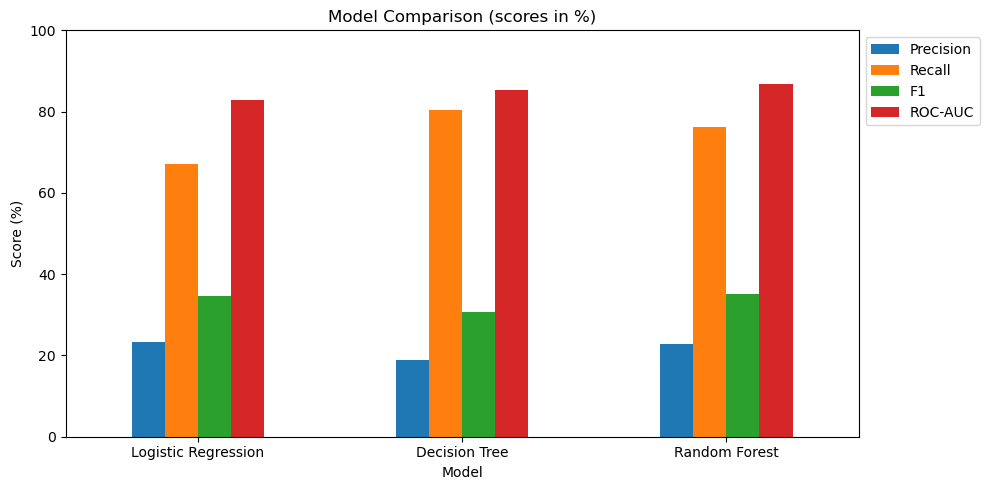

In [32]:
import matplotlib.pyplot as plt

ax = results.plot(kind='bar', figsize=(10, 5), rot=0)
ax.set_title('Model Comparison (scores in %)')
ax.set_ylabel('Score (%)')
ax.set_ylim(0, 100)
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

In [33]:
import pickle
from sklearn.pipeline import Pipeline

final_model = Pipeline([
    ('prep', preprocessor),
    ('rf', rf)
])

with open('credit_scoring_model.pkl', 'wb') as f:
    pickle.dump(final_model, f)

In [34]:
# testing 


In [35]:
with open('credit_scoring_model.pkl', 'rb') as f:
    loaded_model = pickle.load(f)

import numpy as np
loaded_prob = loaded_model.predict_proba(X_test)[:, 1]
print(np.allclose(loaded_prob, rf_prob))

True


In [36]:
# dummy costumer 


new_data = pd.DataFrame([
    {   # Customer 1: looks risky
        'RevolvingUtilizationOfUnsecuredLines': 0.95,
        'age': 28,
        'NumberOfTime30-59DaysPastDueNotWorse': 2,
        'DebtRatio': 0.8,
        'MonthlyIncome': 2500,
        'NumberOfOpenCreditLinesAndLoans': 6,
        'NumberOfTimes90DaysLate': 2,
        'NumberRealEstateLoansOrLines': 0,
        'NumberOfTime60-89DaysPastDueNotWorse': 1,
        'NumberOfDependents': 3
    },
    {   # Customer 2: looks safe (income not given)
        'RevolvingUtilizationOfUnsecuredLines': 0.10,
        'age': 52,
        'NumberOfTime30-59DaysPastDueNotWorse': 0,
        'DebtRatio': 0.2,
        'MonthlyIncome': np.nan,
        'NumberOfOpenCreditLinesAndLoans': 8,
        'NumberOfTimes90DaysLate': 0,
        'NumberRealEstateLoansOrLines': 1,
        'NumberOfTime60-89DaysPastDueNotWorse': 0,
        'NumberOfDependents': 1
    }
])

In [37]:
new_data

,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,0.95,28,2,0.8,2500.0,6,2,0,1,3
1,0.10,52,0,0.2,NaN,8,0,1,0,1


In [38]:
new_data_fe = add_features(new_data)
new_data_fe = new_data_fe[X.columns]

prob = loaded_model.predict_proba(new_data_fe)[:, 1]
label = loaded_model.predict(new_data_fe)

result = new_data.copy()
result['Default_Probability'] = prob.round(3)
result['Prediction'] = np.where(label == 1, 'Risky', 'Safe')

result[['age', 'MonthlyIncome', 'Default_Probability', 'Prediction']]

,age,MonthlyIncome,Default_Probability,Prediction
0,28,2500.0,0.945,Risky
1,52,NaN,0.131,Safe
